# Analyse exploratoire des données
## Compétition Kaggle-playgroud Series S4E6
L'objectif est de prédire le status académique des étudiant: Graduate , Enrolled ou Dropout.

Avant de construire Le modèle on va examiner la structure et la qualité des données.

In [1]:
import pandas as pd 
from pathlib import Path

#Le dossier qui contient les fichier CSV 
data_path=Path("../data")

#Chargement des jeux  de données
train=pd.read_csv(data_path/ "train.csv")
test=pd.read_csv(data_path/"test.csv")

#Affichage de la dimension des données 
print("La dimension de train est:",train.shape)
print("La dimension de test est:",test.shape)

#Affichage des premieres observations
train.head()

La dimension de train est: (76518, 38)
La dimension de test est: (51012, 37)


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,0,1,1,1,9238,1,1,126.0,1,1,...,0,6,7,6,12.428571,0,11.1,0.6,2.02,Graduate
1,1,1,17,1,9238,1,1,125.0,1,19,...,0,6,9,0,0.000000,0,11.1,0.6,2.02,Dropout
2,2,1,17,2,9254,1,1,137.0,1,3,...,0,6,0,0,0.000000,0,16.2,0.3,-0.92,Dropout
3,3,1,1,3,9500,1,1,131.0,1,19,...,0,8,11,7,12.820000,0,11.1,0.6,2.02,Enrolled
4,4,1,1,2,9500,1,1,132.0,1,19,...,0,7,12,6,12.933333,0,7.6,2.6,0.32,Graduate


##  2.Vérification de la structure de nos données
On va examiner les types de variables et la présence eventuelle de valeurs manquantes 

In [2]:
# Informations générales sur les données train 
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 76518 entries, 0 to 76517
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   id                                              76518 non-null  int64  
 1   Marital status                                  76518 non-null  int64  
 2   Application mode                                76518 non-null  int64  
 3   Application order                               76518 non-null  int64  
 4   Course                                          76518 non-null  int64  
 5   Daytime/evening attendance                      76518 non-null  int64  
 6   Previous qualification                          76518 non-null  int64  
 7   Previous qualification (grade)                  76518 non-null  float64
 8   Nacionality                                     76518 non-null  int64  
 9   Mother's qualification                          76

In [3]:
print("Les colonnes qui sont présente uniquement dans train:",set(train.columns)-set(test.columns))
print("Les colonnes qui sont présente uniquement dans test:",set(test.columns)-set(train.columns))

Les colonnes qui sont présente uniquement dans train: {'Target'}
Les colonnes qui sont présente uniquement dans test: set()


In [4]:
# vérifions le nombre de valeurs manquante pour chaque variables 
print("Le nombre de valeurs manquantes dans les données train est:",train.isna().sum().sum())
print("Le nombre de valeurs manquantes dans les données test est",test.isna().sum().sum())

Le nombre de valeurs manquantes dans les données train est: 0
Le nombre de valeurs manquantes dans les données test est 0


In [5]:
# La somme des  nombres de lignes identiques dans nos données 
print("Le nombre de lignes identiques dans les données train est:",train.duplicated().sum())
print("Le nombre de lignes identiques dans les données test est:",test.duplicated().sum())

Le nombre de lignes identiques dans les données train est: 0
Le nombre de lignes identiques dans les données test est: 0


In [6]:
# Conter le nombre d'étudiant pour chaque catégorie de target 
train["Target"].value_counts()

Target
Graduate    36282
Dropout     25296
Enrolled    14940
Name: count, dtype: int64

In [7]:
# Afficher le pourcentage d'étudiant dans chaque categorie de Target
train["Target"].value_counts(normalize=True)*100

Target
Graduate    47.416294
Dropout     33.058888
Enrolled    19.524818
Name: proportion, dtype: float64

On remarque que  la classe Graduate est la plus representée avec 47,42% ,suivie de Dropout avec 33,06%  et de Enrolled avec 19,52%.
Donc les classes ne sont pas réparties de manière équilibrée.Cette défference devra etre prise en compte lors de l'évaluation de nos modèles.

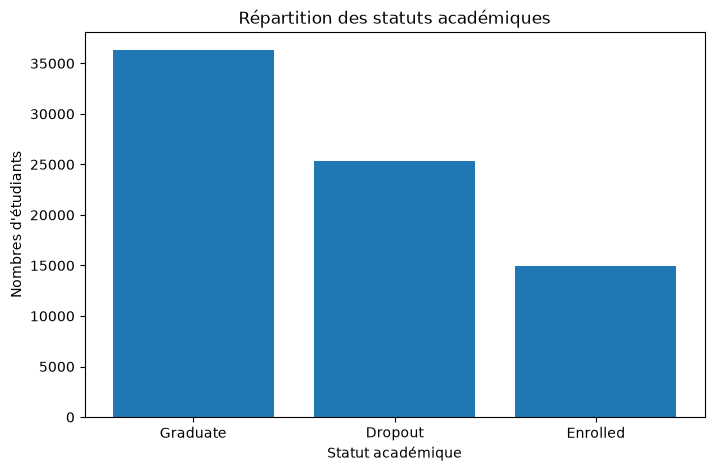

In [8]:
import matplotlib.pyplot as plt 

# Affichage du diagramme en barres des différentes catégotries de la variable Target 
effectifs= train["Target"].value_counts()

plt.figure(figsize=(8,5))
plt.bar(effectifs.index, effectifs.values)
plt.title("Répartition des statuts académiques")
plt.xlabel("Statut académique")
plt.ylabel("Nombres d'étudiants")
plt.show()

###  Nombre d'unité validée au 1er semestre selon le statut académique:

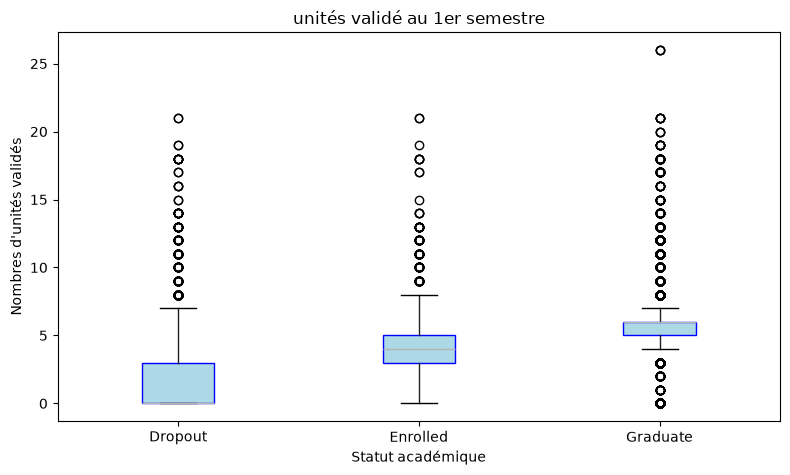

In [9]:
#Affichage de la boxplot de nombre d'unité valide au 1er semestre 
train.boxplot(column="Curricular units 1st sem (approved)",by="Target",grid=False,figsize=(8,5),
              patch_artist=True,boxprops=dict(facecolor="lightblue",edgecolor="blue"))
plt.title("unités validé au 1er semestre")
plt.suptitle("")
plt.xlabel("Statut académique")
plt.ylabel("Nombres d'unités validés")
plt.tight_layout()
plt.show()


On observe que les étudiants diplomés(Graduate) ont généralement validée plus d'unités au premier semestre avec une mediane de 6 contre 4 pour les étudiants encore inscrit (Enrolled)  et 0 pour les étudiant qui ont abandonné(Dropout).
Donc ces résultat suggérent que le nombre d'unités vaslidées au 1er semestre est lié à la réussite académique et pourait être une variable importane pour notre modèle.  

###  Nombre d'unité validée au 2ème semestre selon le statut académique:

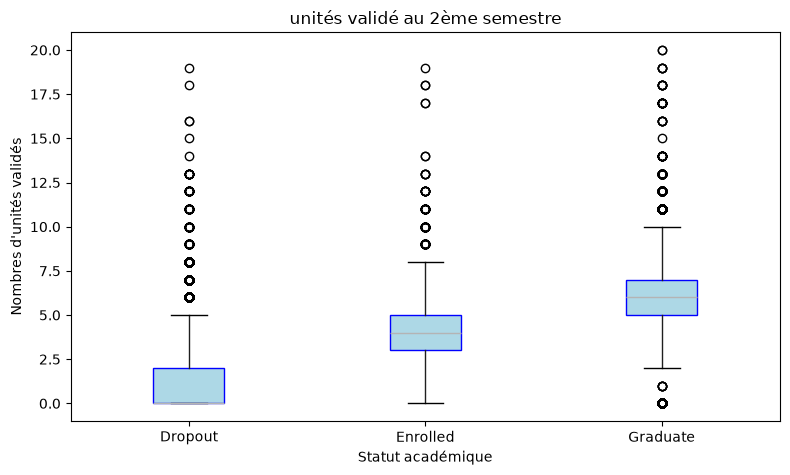

In [10]:
#Affichage de la boxplot de nombre d'unité valide au 2ème semestre 
train.boxplot(column="Curricular units 2nd sem (approved)",by="Target",grid=False,figsize=(8,5),
              patch_artist=True,boxprops=dict(facecolor="lightblue",edgecolor="blue"))
plt.title("unités validé au 2ème semestre")
plt.suptitle("")
plt.xlabel("Statut académique")
plt.ylabel("Nombres d'unités validés")
plt.tight_layout()
plt.show()


On observe une tendance sémilaire à celle du 1er  semestre: les étudiant diplômés (Graduate) valident généralement plus d'unités que les étudiants encore inscrit(Enrolled) ou ayant abandonnée(Dropout).

Donc les résultat des deux semestre semblent être des variables intérréssantes pour prédire le statut académique des étudiant. 

### Âge à l'inscription selon le statut académique: 

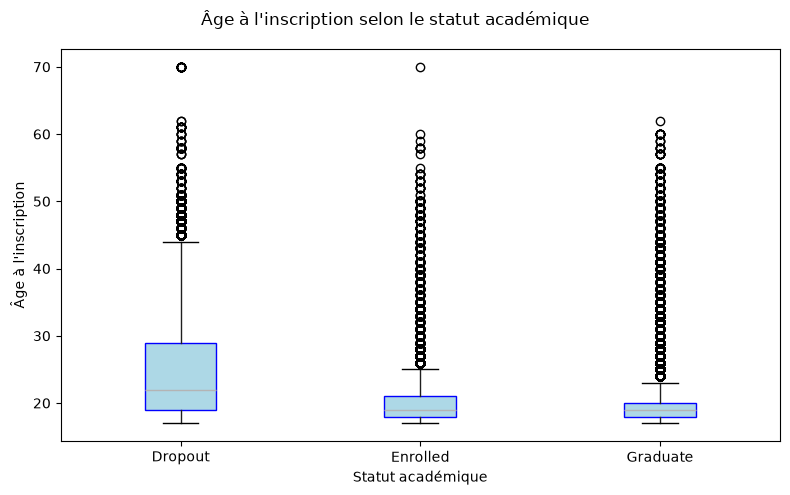

In [11]:
#Affichage de la boxplot de l'âge à l'inscription selon le statut académique  
train.boxplot(column="Age at enrollment",by="Target",grid=False,figsize=(8,5),
              patch_artist=True,boxprops=dict(facecolor="lightblue",edgecolor="blue"))
plt.title("")
plt.suptitle("Âge à l'inscription selon le statut académique")
plt.xlabel("Statut académique")
plt.ylabel("Âge à l'inscription")
plt.tight_layout()
plt.show()


On observe que les étudiant ayant abandonnée (Dropout) sont plus agés à l'inscription et présente une plus grande disperssion des âges.À l'inverse les etudiants diplomés (Graduated) et les étudiants en cours de formation (Enrolled) sont plus jeunes.

Ainsi l'âge à l'inscription pourrait être un bon facteur pour prédire le statut académique. 

### Situation des frais de scolarité selon le statut académique:

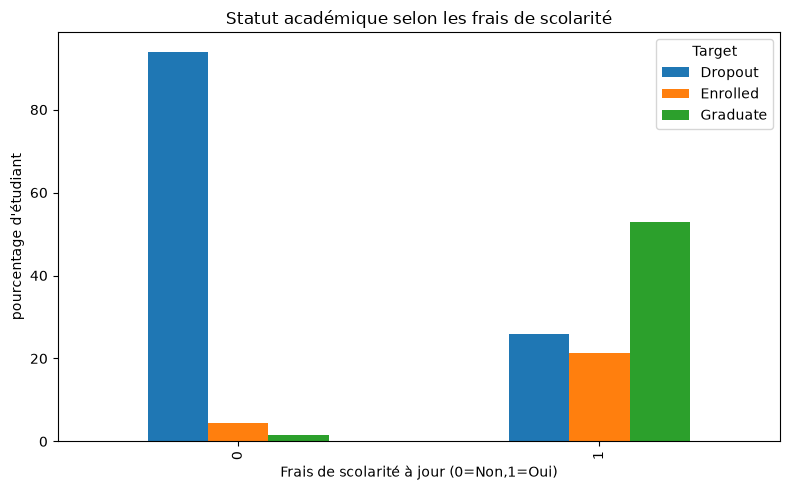

In [12]:
tableau= pd.crosstab(train["Tuition fees up to date"],train["Target"],normalize="index")*100

tableau.plot(kind="bar",figsize=(8,5))
plt.title("Statut académique selon les frais de scolarité")
plt.xlabel("Frais de scolarité à jour (0=Non,1=Oui)")
plt.ylabel("pourcentage d'étudiant")
plt.tight_layout()
plt.show()

On remarque que plus de 90% des étudionts qui ne sont pas à jour avec leur frais de scolarité ont abandonné leur études(Dropout).
À l'inverse parmi les étudiants qui sont à jour avec leur frais de scolarté on trouve un peu plus de la moyenne qui sont Diplomés (Graduate) et 25% ont abandonnés.

Ainsi ces résultats montrent que la situation des  frais de scolarité est fortement liée au statut académique et pourrait être une variable important pour notre modèle de prédiction.

### Statut académique selon l'obtention d'une bourse:

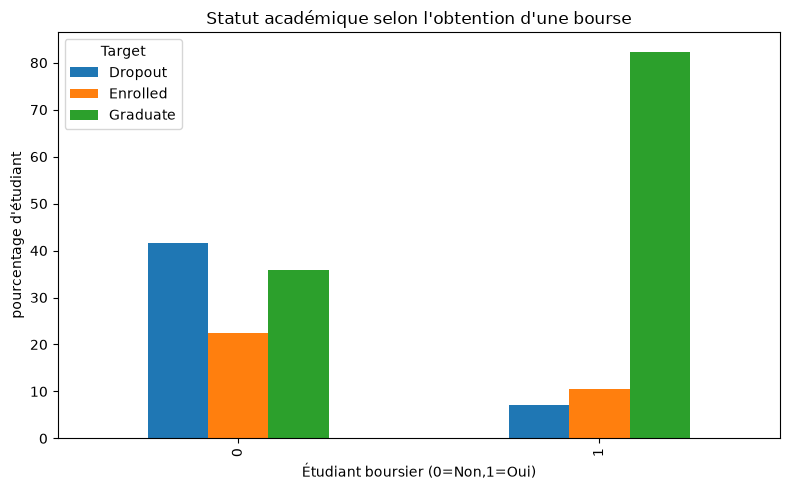

In [13]:
tableau= pd.crosstab(train["Scholarship holder"],train["Target"],normalize="index")*100

tableau.plot(kind="bar",figsize=(8,5))
plt.title("Statut académique selon l'obtention d'une bourse")
plt.xlabel("Étudiant boursier (0=Non,1=Oui)")
plt.ylabel("pourcentage d'étudiant")
plt.tight_layout()
plt.show()

D'après les résultats, on voit que les étudiants boursiers  réussissent généralement mieux ,plus de 80% ont obtenus leur diplôme, contre seulement 36% des non boursiers.

À l'inverse le taux d'abondon est boucoup plus élevé pour les étudiants non boursier et il est de 42% , et seulement 7% pour les boursiers.

Donc l'obtention d'une bourse est fortement associée au statuts académique et pourrait être une variable importante pour notre modele.

### Analyse des corrélations entre les variables scolaires: 

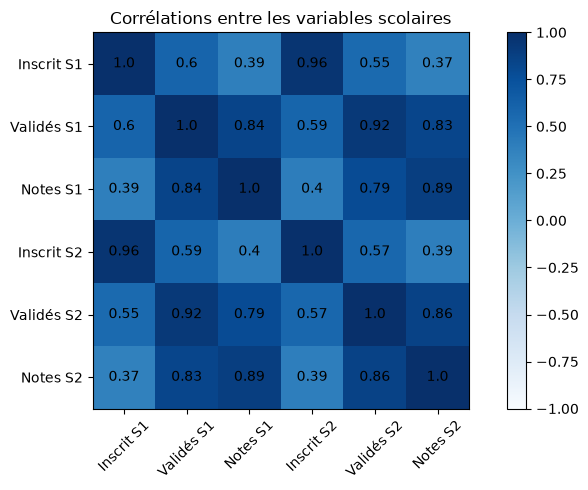

In [14]:

# Sélection des variables scolaires
colonnes = ["Curricular units 1st sem (enrolled)","Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)","Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (approved)","Curricular units 2nd sem (grade)"
]

correlation=train[colonnes].corr()

plt.figure(figsize=(8,5))
plt.imshow(correlation,cmap="Blues",vmax=1,vmin=-1)
for i in range(6):
  for j in range(6):
    plt.text(j,i,round(correlation.iloc[i,j],2),ha="center",va="center")

noms=["Inscrit S1","Validés S1","Notes S1","Inscrit S2","Validés S2","Notes S2"]
plt.xticks(range(6),noms,rotation=45)
plt.yticks(range(6),noms)
plt.colorbar()
plt.title("Corrélations entre les variables scolaires")
plt.tight_layout()
plt.show()

On remarque de forte corrélation entre les résultats scolaires des deux semestres ,et notamment pour le nombres d'unités validées (0.92) et les notes moyennes (0.89).

Ainsi cela montre que les étudiants ayant des bons résultats au 1er semestre ont tendances à les conserver au deuxième semestre.

### Conslusion de l'analyse exploratroire: 
Cette analyse nous a permis de mieux comprendre notre jeu de données et d'identifier des variables qui sont associées au statut académique des étudiants.

Les résultats scolaires ,les frais de scolarité, l'obtention d'une bourse et l'âge à l'inscription semblent être liés au statut académique des étudiants.Ces variables pourrait être utiles pour la prédiction.

Ces obeservation restent une première base pour la suite du projet , où on  évaluera l'utilité des ces variables à travers les modèles de classification.